# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [15]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

In [18]:
# cargar archivos
plans = pd.read_csv("/datasets/plans.csv")
users = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")

In [20]:
# mostrar las primeras 5 filas de users
display(users.head())

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [18]:
# mostrar las primeras 5 filas de usage
display(usage.head())

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [21]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [22]:
# inspección de plans con .info()
print("\nEstructura de plans:")
plans.info()


Estructura de plans:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [21]:
# inspección de users con .info()
print("\nEstructura de users:")
users.info()


Estructura de users:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [23]:
# inspección de usage con .info()
print("\nEstructura de usage:")
usage.info()



Estructura de usage:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [24]:
# cantidad de nulos para users
print("Cantidad de valores nulos en users:")
print(users.isna().sum())
print("\nProporción de valores nulos en users:")
print(users.isna().mean())


Cantidad de valores nulos en users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos en users:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


**`city`:** Tiene 469 valores faltantes (11,725 %). Recomiendo conservar las filas y usar «Sin ciudad registrada» en los reportes por ubicación para evitar asignar ciudades sin evidencia.
- **`churn_date`:** Tiene 3.534 valores faltantes (88,35 %). Recomiendo conservar la columna sin imputar fechas. Si la documentación confirma que un nulo significa que no se registró una baja, úsalo para identificar a los usuarios sin baja registrada.
- **Demás columnas:** No presentan valores faltantes y no requieren tratamiento por nulos.

In [26]:
# cantidad de nulos para usage
print("\nCantidad de valores nulos en usage:")
print(usage.isna().sum())

print("\nProporción de valores nulos en usage:")
print(usage.isna().mean())


Cantidad de valores nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos en usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


- **`date`:** Tiene 50 nulos (0,125 %). Recomiendo recuperar las fechas de la fuente; si no es posible, excluir esas filas únicamente de los análisis por fecha.
- **`duration`:** Tiene 22.076 nulos (55,19 %). Recomiendo revisar los faltantes por `type` y conservarlos sin imputar si la duración no aplica a ese tipo de registro.
- **`length`:** Tiene 17.896 nulos (44,74 %). Recomiendo revisar los faltantes por `type` y conservarlos sin imputar si la longitud no aplica a ese tipo de registro.
- **`id`, `user_id` y `type`:** No presentan valores faltantes y no requieren tratamiento por nulos. 

## ✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [27]:
# explorar columnas numéricas de users
display(users[["user_id", "age"]].describe())

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` Los identificadores van de 10.000 a 13.999 y el resumen no muestra valores sentinels evidentes. Conservaría la columna y verificaría que cada identificador sea único antes de unir los datos.
- La columna `age` El mínimo es -999, un valor centinela que distorsiona el promedio y aumenta la desviación estándar. Reemplazaría -999 por un valor nulo, conservaría las filas y volvería a calcular el resumen estadístico.

In [30]:
# explorar columnas numéricas de usage
display(usage[["id", "user_id", "duration", "length"]].describe())

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id No se observan valores centinela evidentes. Verificaría que id sea único y que todos los user_id existan en users. Un mismo usuario puede aparecer en varios eventos.
- La columna duration: El mínimo es 0 y el máximo es 120, frente a una mediana de 3,5. Revisaría los ceros y los valores altos según type y las unidades de medida antes de decidir si requieren corrección.
- La Columna length: El mínimo es 0 y el máximo es 1490, frente a una mediana de 50. Revisaría si los ceros son válidos y si el valor 1490 corresponde a un registro real o a un error.

In [31]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
columnas_user = ["city", "plan"]

for col in columnas_user:
    print(f"\nValores únicos de {col}:")
    print(users[col].unique())


Valores únicos de city:
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

Valores únicos de plan:
['Basico' 'Premium']


- La columna `city` El valor ? es un posible centinela de ciudad desconocida. Si se confirma, lo reemplazaría por un nulo (NaN) y volvería a contar los faltantes. También revisaría las abreviaturas CDMX, GDL y MTY para unificar los nombres de las ciudades.
- La columna `plan` Aparecen Basico y Premium, sin centinelas evidentes. Verificaría que ambas etiquetas coincidan con el catálogo plans antes de unir los datasets.

In [29]:
# explorar columna categórica de usage
print("\nValores únicos de type:")
print(usage["type"].unique())


Valores únicos de type:
['call' 'text']


- La columna `type`Solo aparecen dos categorías: call (llamada) y text (mensaje). No se observan valores inválidos ni centinelas, así que conservaría la columna sin cambios. La usaría para verificar si los nulos de duration y length se deben a que cada métrica solo aplica a un tipo de evento.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [38]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors="coerce")


In [39]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors="coerce")

In [36]:
# Revisar los años presentes en `reg_date` de users
anios_reg = users['reg_date'].dt.year
print(anios_reg.value_counts(dropna=False).sort_index())
print("Registros posteriores a 2024:", (anios_reg > 2024).sum())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64
Registros posteriores a 2024: 40


En `reg_date`, (users): Se registraron 1.314 altas en 2022, 1.316 en 2023 y 1.330 en 2024. No aparecen años demasiado antiguos en el resumen. Sin embargo, 40 fechas corresponden a 2026, fuera del período del dataset, cuyo corte es 2024.  
Conservaría las fechas de 2022 a 2024 y verificaría las 40 fechas de 2026 con la fuente original. Si no puedo recuperar la fecha correcta, las marcaría como NaT y excluiría esos registros solo de los análisis que dependan de la fecha de alta.

In [37]:
# Revisar los años presentes en `date` de usage
anios_uso = usage['date'].dt.year
print(anios_uso.value_counts(dropna=False).sort_index())
print("Eventos posteriores a 2024:", (anios_uso > 2024).sum())

2024.0    39950
NaN          50
Name: date, dtype: int64
Eventos posteriores a 2024: 0


En `date`, date (usage): Hay 39.950 eventos con fecha en 2024 y 50 sin fecha válida (0,125 %). No se observan años antiguos ni posteriores al corte de 2024. El conteo de faltantes coincide con el que se obtuvo antes de convertir las fechas.
Conservaría las fechas de 2024 e intentaría recuperar las 50 fechas faltantes de la fuente original. Si no es posible, las dejaría como NaT y excluiría esos eventos únicamente de los análisis que dependan de la fecha.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [40]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [43]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [48]:
# Marcar fechas futuras como NA para reg_date
fechas_fuera_de_rango = users['reg_date'].dt.year > 2024
users.loc[fechas_fuera_de_rango, 'reg_date'] = pd.NaT

# Verificar cambios
print("Fechas marcadas como nulas:", fechas_fuera_de_rango.sum())
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

Fechas marcadas como nulas: 0
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [49]:
# Verificación MAR en usage (Missing At Random) para duration
print(
    usage["duration"].isna()
    .groupby(usage["type"])
    .agg(nulos="sum", proporcion="mean")
    .assign(porcentaje=lambda tabla: tabla["proporcion"] * 100)
    [["nulos", "porcentaje"]]
)

      nulos  porcentaje
type                   
call      0    0.000000
text  22076   99.927576


In [50]:
# Verificación MAR en usage (Missing At Random) para length
print(
    usage["length"].isna()
    .groupby(usage["type"])
    .agg(nulos="sum", proporcion="mean")
    .assign(porcentaje=lambda tabla: tabla["proporcion"] * 100)
    [["nulos", "porcentaje"]]
)

      nulos  porcentaje
type                   
call  17896   99.932991
text      0    0.000000


duration: No hay nulos en las llamadas (call), mientras que 22.076 mensajes (99,93 %) tienen la duración vacía. Si la duración solo aplica a llamadas, conservaría esos nulos como «no aplica» y revisaría los 16 mensajes que sí tienen duración.
length: No hay nulos en los mensajes (text), mientras que 17.896 llamadas (99,93 %) tienen length vacía. Si la length solo aplica a mensajes, conservaría esos nulos como «no aplica» y revisaría las 12 llamadas que sí tienen length.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares

usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)
usage["minutos_llamada"] = usage["duration"].where(usage["type"] == "call", 0)


# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id")[["is_text", "is_call", "minutos_llamada"]]
    .sum()
    .reset_index()
)

# observar resultado
display(usage_agg.head(3))

,user_id,is_text,is_call,minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "minutos_llamada": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [30]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = [
    "age",
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]

display(user_profile[columnas_numericas].describe())

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,33.739750,5.524381,4.478120,22.836934
std,123.232257,2.358416,2.144238,16.590213
min,-999.000000,0.000000,0.000000,0.000000
25%,32.000000,4.000000,3.000000,11.095000
50%,47.000000,5.000000,4.000000,19.740000
75%,63.000000,7.000000,6.000000,31.185000
max,79.000000,17.000000,15.000000,155.690000


In [36]:
# Distribución porcentual del tipo de plan
porcentaje_plan = user_profile["plan"].value_counts(normalize=True) * 100
display(porcentaje_plan.round(2))

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

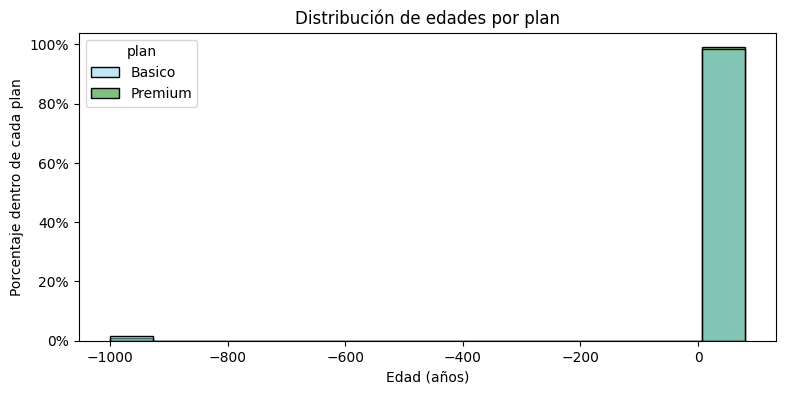

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Histograma de edad por plan
plt.figure(figsize=(9, 4))

ax = sns.histplot(
    data=user_profile,
    x="age",
    hue="plan",
    palette=["skyblue", "green"],
    bins=15,
    stat="probability",
    common_norm=False
)

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

plt.title("Distribución de edades por plan")
plt.xlabel("Edad (años)")
plt.ylabel("Porcentaje dentro de cada plan")
plt.show()

💡Insights: 
- Distribución Ambos planes concentran las edades en valores positivos, pero la presencia del centinela -999 estira el eje hacia la izquierda y oculta la distribución real. Con este gráfico no se pueden identificar diferencias claras de edad entre Básico y Premium.

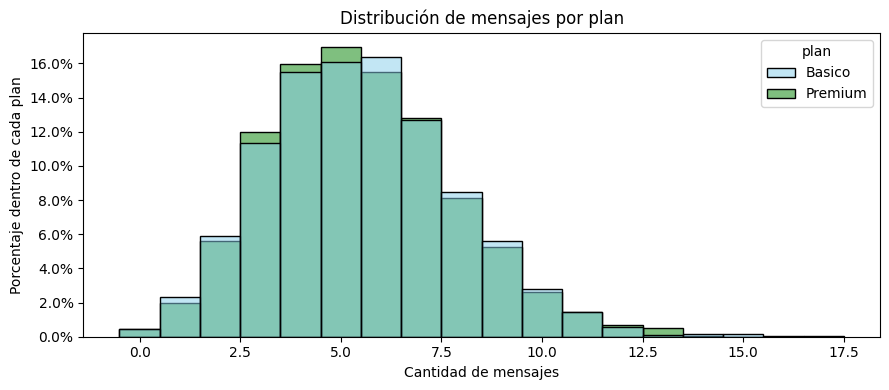

In [37]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(9, 4))

ax = sns.histplot(
    data=user_profile,
    x="cant_mensajes",
    hue="plan",
    palette=["skyblue", "green"],
    discrete=True,
    stat="probability",
    common_norm=False
)

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.title("Distribución de mensajes por plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Porcentaje dentro de cada plan")
plt.tight_layout()
plt.show()

💡Insights: 
- Distribución: Ambos planes presentan patrones muy similares: la mayor concentración está entre 3 y 7 mensajes, con un pico alrededor de 5 mensajes. La distribución tiene un ligero sesgo a la derecha, con pocos usuarios que superan los 10 mensajes. No se observan diferencias claras de uso entre Básico y Premium.

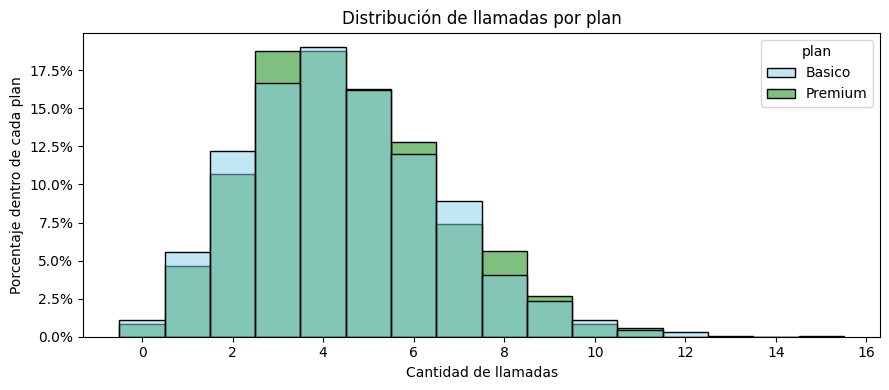

In [38]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(9, 4))

ax = sns.histplot(
    data=user_profile,
    x="cant_llamadas",
    hue="plan",
    palette=["skyblue", "green"],
    discrete=True,
    stat="probability",
    common_norm=False
)

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.title("Distribución de llamadas por plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Porcentaje dentro de cada plan")
plt.tight_layout()
plt.show()

💡Insights: 
- Distribución: Ambos planes presentan patrones similares, con mayor concentración entre 2 y 6 llamadas y un pico alrededor de 3–4 llamadas. La distribución está sesgada a la derecha, con pocos usuarios que superan las 10 llamadas. No se observan diferencias claras entre Básico y Premium.

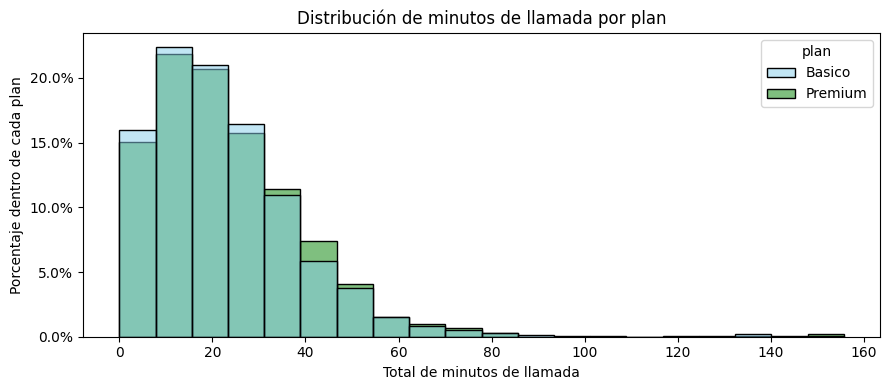

In [39]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(9, 4))

ax = sns.histplot(
    data=user_profile,
    x="cant_minutos_llamada",
    hue="plan",
    palette=["skyblue", "green"],
    bins=20,
    stat="probability",
    common_norm=False
)

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.title("Distribución de minutos de llamada por plan")
plt.xlabel("Total de minutos de llamada")
plt.ylabel("Porcentaje dentro de cada plan")
plt.tight_layout()
plt.show()

💡Insights: 
- - Ambos planes presentan una distribución sesgada a la derecha, con mayor concentración entre 0 y 40 minutos y un pico alrededor de 10–15 minutos. Pocos usuarios acumulan más de 60 minutos y algunos alcanzan cerca de 150. Las distribuciones se superponen ampliamente, sin diferencias visuales claras entre Básico y Premium.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

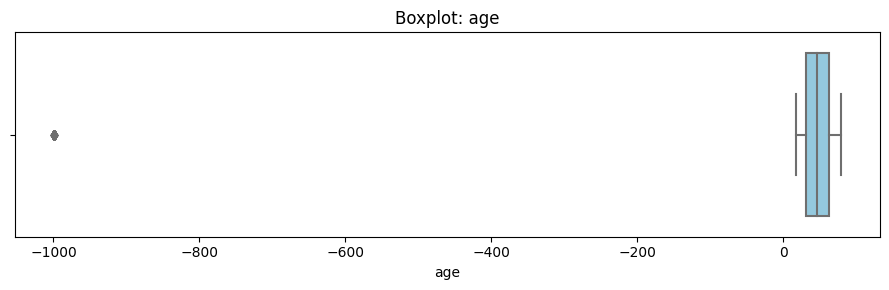

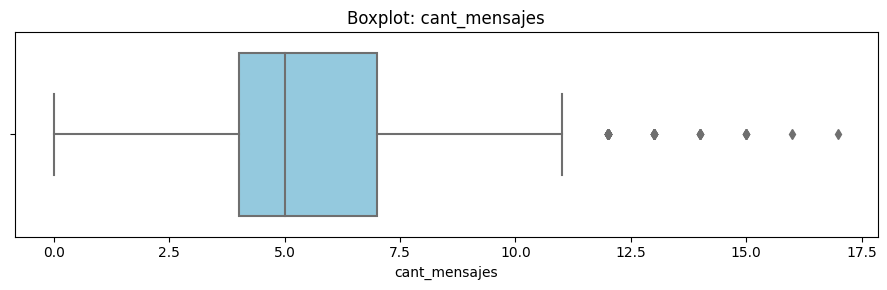

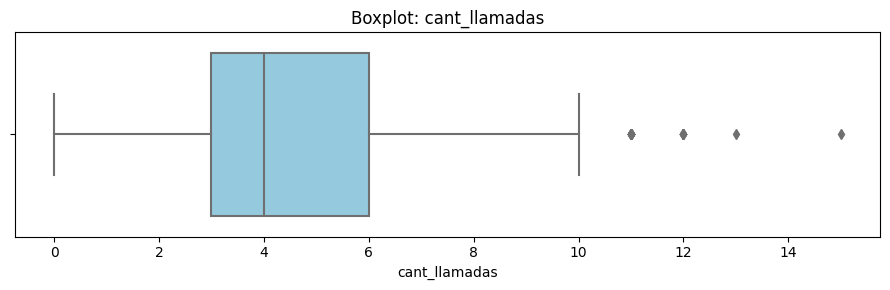

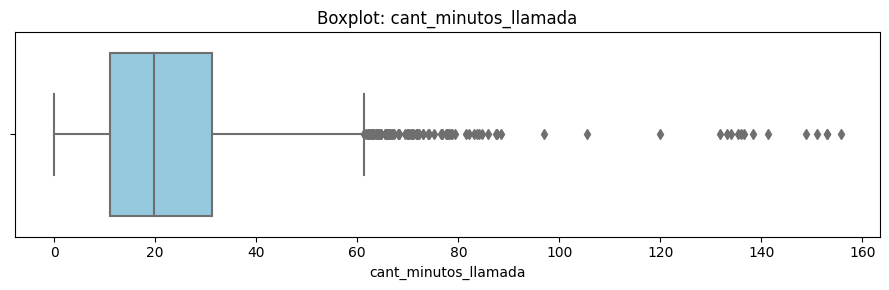

In [40]:
# Visualizando usando BoxPlot 
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_numericas:
    plt.figure(figsize=(9, 3))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

💡Insights: 
- age: Presenta un valor extremo inferior en -999, que es un centinela inválido. Sigue apareciendo en este gráfico, por lo que debe corregirse y actualizar user_profile antes de repetir el boxplot.
- cant_mensajes: Presenta outliers superiores desde aproximadamente 12 mensajes, con un máximo cercano a 17.
- cant_llamadas: Presenta outliers superiores desde aproximadamente 11 llamadas, con un máximo cercano a 15.
- cant_minutos_llamada: Presenta numerosos outliers superiores a aproximadamente 60 minutos, alcanzando cerca de 155 minutos. La cola hacia valores altos indica sesgo a la derecha.
Los valores altos de uso requieren revisión, pero no deben eliminarse automáticamente: pueden representar usuarios con mayor actividad.

In [41]:
# Calcular límites con el método IQR
columnas_limites = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_superior = Q3 + 1.5 * IQR

    print(f"\n{col}")
    print(f"Límite superior: {limite_superior:.2f}")
    print(f"Máximo: {user_profile[col].max():.2f}")
    print(f"Cantidad de outliers: {(user_profile[col] > limite_superior).sum()}")

# Revisar resumen estadístico
user_profile[columnas_limites].describe()



cant_mensajes
Límite superior: 11.50
Máximo: 17.00
Cantidad de outliers: 46

cant_llamadas
Límite superior: 10.50
Máximo: 15.00
Cantidad de outliers: 30

cant_minutos_llamada
Límite superior: 61.32
Máximo: 155.69
Cantidad de outliers: 96


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.836934
std,2.358416,2.144238,16.590213
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.095000
50%,5.000000,4.000000,19.740000
75%,7.000000,6.000000,31.185000
max,17.000000,15.000000,155.690000


In [42]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.836934
std,2.358416,2.144238,16.590213
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.095000
50%,5.000000,4.000000,19.740000
75%,7.000000,6.000000,31.185000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?

cant_mensajes: Mantendría los outliers. El límite superior IQR es 11,5 mensajes y el máximo es 17; estos valores pueden corresponder a usuarios más activos.
cant_llamadas: Mantendría los outliers. El límite superior es 10,5 llamadas y el máximo es 15; superar ese límite no implica un error de registro.
cant_minutos_llamada: Los conservaría sujetos a revisión. El límite superior es 61,32 minutos y el máximo es 155,69. Verificaría las duraciones originales y posibles duplicados; si los registros son válidos, representan un uso elevado real.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [43]:
import numpy as np

# Crear columna grupo_uso
condiciones = [
    (user_profile["cant_llamadas"] < 5) &
    (user_profile["cant_mensajes"] < 5),

    (user_profile["cant_llamadas"] < 10) &
    (user_profile["cant_mensajes"] < 10)
]

user_profile["grupo_uso"] = np.select(
    condiciones,
    ["Bajo uso", "Uso medio"],
    default="Alto uso"
)


In [44]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [45]:
# Crear columna grupo_edad
condiciones = [
    user_profile["age"] < 30,
    user_profile["age"] < 60
]

user_profile["grupo_edad"] = np.select(
    condiciones,
    ["Joven", "Adulto"],
    default="Adulto Mayor"
)

In [46]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

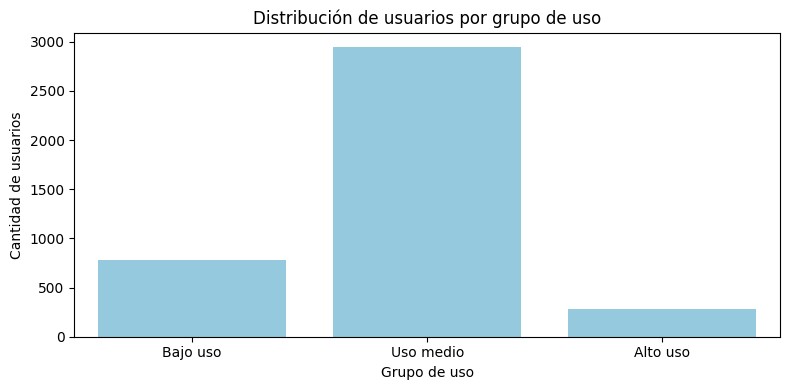

In [47]:
# Visualización de los segmentos por uso
plt.figure(figsize=(8, 4))
sns.countplot(
    data=user_profile,
    x="grupo_uso",
    order=["Bajo uso", "Uso medio", "Alto uso"],
    color="skyblue"
)
plt.title("Distribución de usuarios por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de usuarios")
plt.tight_layout()
plt.show()

plt.show()

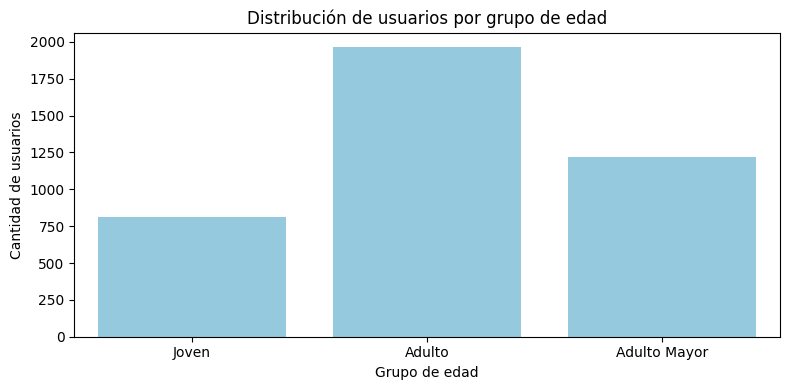

In [48]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 4))
sns.countplot(
    data=user_profile,
    x="grupo_edad",
    order=["Joven", "Adulto", "Adulto Mayor"],
    color="skyblue"
)
plt.title("Distribución de usuarios por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios")
plt.tight_layout()
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
-En users, faltaban 469 ciudades (11,73 %) y se encontró el centinela "?", que debe tratarse como dato ausente. También aparecieron edades inválidas de -999, reemplazadas por la mediana de las edades válidas.
-Se detectaron 40 fechas de registro de 2026 (1 %), posteriores al corte de 2024; se marcaron como fechas faltantes. Los 3.534 nulos de churn_date (88,35 %) se conservaron, sujetos a confirmar que representan usuarios sin baja registrada.
-En usage, 50 eventos carecían de fecha (0,125 %). Los faltantes de duration y length estaban asociados al tipo de evento: principalmente duración vacía en mensajes y longitud vacía en llamadas. Se conservaron como «no aplica», pendientes de validar los 16 mensajes con duración y las 12 llamadas con longitud.


🔍 **Segmentos por Edad**
- Se definieron tres grupos: Joven, menores de 30 años; Adulto, de 30 a 59; y Adulto Mayor, desde los 60.
- Esta clasificación permite diseñar campañas diferenciadas. Sin embargo, todavía falta cruzar edad y consumo para determinar qué grupo llama o envía más mensajes; no debe suponerse su comportamiento únicamente por la edad.
   


📊 **Segmentos por Nivel de Uso**
- Bajo uso: menos de 5 llamadas y menos de 5 mensajes. Uso medio: menos de 10 llamadas y mensajes, excluyendo al grupo anterior. Alto uso: 10 o más llamadas o mensajes.
- Los histogramas de Básico y Premium muestran patrones similares: concentración alrededor de 5 mensajes, 3–4 llamadas y mayor frecuencia de totales de llamada entre 0 y 40 minutos. No se observan diferencias visuales claras entre planes.
- Se encontraron máximos de 17 mensajes, 15 llamadas y 155,69 minutos. Superan los límites superiores IQR de 11,5 mensajes, 10,5 llamadas y 61,32 minutos, respectivamente. Son posibles usuarios intensivos, cuyos registros conviene validar antes de corregirlos o eliminarlos.


➡️ Esto sugiere que el consumo observado diferencia poco a los planes actuales. Los usuarios de alto uso son candidatos para ofertas de mayor capacidad, pero no puede afirmarse que sean los más rentables sin analizar ingresos, costos y permanencia. Además, la clasificación actual no considera minutos: un usuario con pocas llamadas largas puede tener un consumo importante.

💡 **Recomendaciones**
- Evaluar un plan de entrada para bajo uso y paquetes adicionales de mensajes o minutos para usuarios intensivos, comparando primero su consumo con las prestaciones y precios actuales.
- Incorporar minutos de llamada a la segmentación y analizar consumo mensual, considerando el tiempo que cada usuario estuvo activo.
Cruzar grupo_edad, grupo_uso y plan para identificar oportunidades comerciales. Priorizar propuestas según consumo real, evitando asumir preferencias por edad.
- Medir ingreso, margen y retención por segmento antes de decidir cuáles son más valiosos o promover cambios de plan.
Validar los registros extremos y resolver el usuario sin métricas antes de segmentar: sus nulos no deben convertirlo automáticamente en «Alto uso». Mantener controles de edades, fechas y campos aplicables a cada evento.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`